# Workshop 6. Simple linear regression

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aaubs/AQM-2026/blob/main/lecture06/workshop06.ipynb)

In this workshop you write the code yourselves. Work in your group or alone, and ask the TAs when you are stuck.

Task 1 is the regression from the lecture in code, fully worked: run it, answer the questions and change one thing.
Tasks 2 to 4 start from an empty cell: visits and age, visits and years as a customer, and the slope and its
standard error by hand for the customers in Nordjylland. The extension tasks are for those who have time left.
Exercises in the style of the textbook, with small numbers and no data, are in the TA's separate notebook for this
session (link on Moodle).

Each core task has two hints: the first names the statistical step, the second names the functions. Try the task
before you open them. The toolbox says where you have seen each function before, so you can look it up in that
notebook. The code patterns, the slides and the lecture notebook are your main references. You are welcome to use an
LLM, but every task can be solved without one, and you should be able to explain the statistics in your answers
yourself.

In every task, say what y and x are and in which units before you fit anything. Each answer is in words a manager can
follow, with the numbers it rests on. The tests are two-sided, as in the statsmodels output.

## Toolbox

The functions you need today, and where you have seen them in use.

| Function | What it does | Seen in |
|---|---|---|
| `smf.ols("y ~ x", data=df).fit()` | Fits the least-squares line of y on x, with an intercept | Lecture 6, Part 1 |
| `model.summary()` | The full output table | Lecture 6, Part 3 |
| `model.params`, `model.bse` | b<sub>0</sub> and b<sub>1</sub>; their standard errors | Lecture 6, Parts 1 and 3 |
| `model.tvalues`, `model.pvalues`, `model.conf_int()` | t, the two-sided p-value for H<sub>0</sub>: β = 0, and the 95% intervals | Lecture 6, Part 3 |
| `model.rsquared`, `np.sqrt(model.scale)` | R² and s<sub>e</sub> | Lecture 6, Part 2 |
| `model.predict(pd.DataFrame({"x": [value]}))` | The line's value at a given x | Lecture 6, Part 4 |
| `df[df["col"] == value]` | The rows where a column has a given value | Lecture 6, Exercise 4; Lecture 4 (Copenhagen and Aarhus orders) |
| `df["col"].mean()`, `.std(ddof=1)`, `.min()`, `.max()` | Mean, standard deviation (dividing by n − 1), smallest and largest value | Lectures 1 and 2 |
| `plt.scatter(x, y)`, `plt.plot(xs, ys)` | Scatter plot; a line through given points | Lecture 6, Part 1 |
| `stats.t.ppf(0.975, df=n - 2)` | The two-sided critical value for α = 0.05 | Lecture 6, Part 3; Lecture 3 |
| `np.sqrt(x)` | Square root | Lecture 1 |

## Code patterns

Two complete patterns for today. Replace `df`, `y` and `x` with your data and column names. The patterns are
templates; they do not run as they stand.

**Fit a line, print the output, and pull out the numbers**

```python
model = smf.ols("y ~ x", data=df).fit()
print(model.summary())
b0, b1 = model.params["Intercept"], model.params["x"]
s_b1 = model.bse["x"]
lo, hi = model.conf_int().loc["x"]
print(f"b0 = {b0:.2f}, b1 = {b1:.3f}, s_b1 = {s_b1:.3f}, interval {lo:.2f} to {hi:.2f}")
print(f"R2 = {model.rsquared:.3f}, s_e = {np.sqrt(model.scale):.2f}")
```

**A scatter plot with the line, and a prediction**

```python
plt.scatter(df["x"], df["y"], s=8, alpha=0.5)
xs = np.array([df["x"].min(), df["x"].max()])
plt.plot(xs, b0 + b1 * xs, color="darkorange")
plt.xlabel("x and its unit"); plt.ylabel("y and its unit")
plt.show()
print(model.predict(pd.DataFrame({"x": [5]})))   # the line's value at x = 5
```

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

url = "https://raw.githubusercontent.com/aaubs/AQM-2026/main/data/"
customers = pd.read_csv(url + "customers_sample.csv")   # 1,000 RetailCorp customers drawn at random
customers.head()

,customer_id,age,region,channel,member,tenure_years,visits_2025,spend_2025,churned
0,CU-01134,53,Sjælland,Web,0,9.7,16,1976.81,1
1,CU-44894,60,Syddanmark,Web,1,10.8,29,3322.09,0
2,CU-04192,19,Hovedstaden,App,0,0.6,37,917.47,0
3,CU-27980,45,Sjælland,Web,0,8.5,20,2538.88,0
4,CU-57669,23,Nordjylland,App,0,0.4,37,966.40,1


## Core tasks

### Task 1. Spend and years as a customer (worked)

The lecture walkthrough in code. Run the cells and answer the questions below them.

y = `spend_2025` (DKK in 2025), x = `tenure_years` (years as a customer on 1 January 2025).

In [2]:
data = customers      # step 3: change to customers[customers["member"] == 1], then to customers[customers["member"] == 0]

model = smf.ols("spend_2025 ~ tenure_years", data=data).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             spend_2025   R-squared:                       0.133
Model:                            OLS   Adj. R-squared:                  0.132
Method:                 Least Squares   F-statistic:                     152.9
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           8.86e-33
Time:                        13:58:19   Log-Likelihood:                -8657.3
No. Observations:                1000   AIC:                         1.732e+04
Df Residuals:                     998   BIC:                         1.733e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept     1494.6958     69.689     21.448   

n = 1000, b0 = 1494.70, b1 = 201.785, s_b1 = 16.319, interval 169.76 to 233.81
R2 = 0.133, s_e = 1393.14


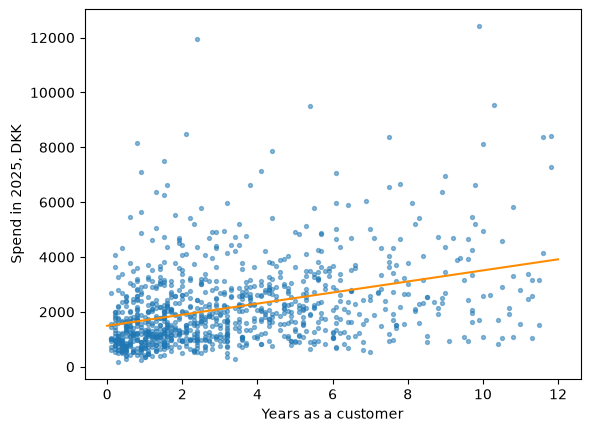

0    2503.621701
dtype: float64


In [3]:
b0, b1 = model.params["Intercept"], model.params["tenure_years"]
lo, hi = model.conf_int().loc["tenure_years"]
print(f"n = {int(model.nobs)}, b0 = {b0:.2f}, b1 = {b1:.3f}, s_b1 = {model.bse['tenure_years']:.3f}, "
      f"interval {lo:.2f} to {hi:.2f}")
print(f"R2 = {model.rsquared:.3f}, s_e = {np.sqrt(model.scale):.2f}")

plt.scatter(data["tenure_years"], data["spend_2025"], s=8, alpha=0.5)
xs = np.array([0, 12])
plt.plot(xs, b0 + b1 * xs, color="darkorange")
plt.xlabel("Years as a customer"); plt.ylabel("Spend in 2025, DKK")
plt.show()
print(model.predict(pd.DataFrame({"tenure_years": [5]})))

**Questions**

1. Find b<sub>1</sub>, s<sub>b1</sub>, t, the p-value, the 95% interval and R² in the output. Say in one sentence each
   what b<sub>1</sub> and R² mean for RetailCorp.
2. Where in the output is the test of H<sub>0</sub>: β<sub>1</sub> = 0, and what do you conclude at α = 0.05?
3. Why does the output show `0.000` for the p-value, and how do you report it?

**Change one thing.** In the first cell, change `data = customers` to club members only,
`customers[customers["member"] == 1]`, and run both cells. Then do the same for non-members (`== 0`). Compare the two
slopes and their intervals.

In [4]:
# Task 1, change one thing: the same regression for club members and for non-members.
# The two given cells above are left unchanged and still show the full sample.

data_members = customers[customers["member"] == 1]
model_members = smf.ols("spend_2025 ~ tenure_years", data=data_members).fit()
print("Club members")
print(model_members.summary())
b0, b1 = model_members.params["Intercept"], model_members.params["tenure_years"]
lo, hi = model_members.conf_int().loc["tenure_years"]
print(f"n = {int(model_members.nobs)}, b0 = {b0:.2f}, b1 = {b1:.3f}, s_b1 = {model_members.bse['tenure_years']:.3f}, "
      f"interval {lo:.2f} to {hi:.2f}")
print(f"R2 = {model_members.rsquared:.3f}, s_e = {np.sqrt(model_members.scale):.2f}")

data_non = customers[customers["member"] == 0]
model_non = smf.ols("spend_2025 ~ tenure_years", data=data_non).fit()
print("\nNon-members")
print(model_non.summary())
b0, b1 = model_non.params["Intercept"], model_non.params["tenure_years"]
lo, hi = model_non.conf_int().loc["tenure_years"]
print(f"n = {int(model_non.nobs)}, b0 = {b0:.2f}, b1 = {b1:.3f}, s_b1 = {model_non.bse['tenure_years']:.3f}, "
      f"interval {lo:.2f} to {hi:.2f}")
print(f"R2 = {model_non.rsquared:.3f}, s_e = {np.sqrt(model_non.scale):.2f}")


Club members
                            OLS Regression Results                            
Dep. Variable:             spend_2025   R-squared:                       0.070
Model:                            OLS   Adj. R-squared:                  0.068
Method:                 Least Squares   F-statistic:                     30.49
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           6.02e-08
Time:                        13:58:19   Log-Likelihood:                -3535.3
No. Observations:                 405   AIC:                             7075.
Df Residuals:                     403   BIC:                             7083.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept     2086.2413    122.394 

**Your answer:**

**1.** In the coefficient table, row `tenure_years`: $b_1$ = 201.79 DKK per year, $s_{b_1}$ = 16.32, $t$ = 12.37, the p-value is printed as 0.000, and the 95% interval is 169.76 to 233.81. $R^2$ = 0.133 is at the top of the output ($n$ = 1,000). The intercept is $b_0$ = 1,494.70 DKK, and $s_e$ = 1,393 DKK. The line predicts 2,504 DKK for customers with five years of tenure.

**What $b_1$ means for RetailCorp.** Customers who differ by one year of tenure differ in average spend in 2025 by about 202 DKK: longer-tenured customers spend more, on average. This describes the customers as they are. It does not show that giving a customer one more year *causes* that customer to spend more (age, loyalty or who stays in the data could also produce this slope).

**What $R^2$ means for RetailCorp.** Years as a customer account for 13.3% of the variation in spend; the other 87% is not accounted for by tenure. A typical customer still lies about 1,393 DKK from the line, so tenure is a useful association but a weak predictor for a single customer.

**2.** The test of $H_0$: $\beta_1$ = 0 against the two-sided $H_1$: $\beta_1 \neq 0$ is the $t$ and `P>|t|` in the `tenure_years` row. (The F-statistic is the same test: $F = t^2$ = 152.9, $p$ = $8.86 \times 10^{-33}$.) Because $p < 0.05$ (in fact $p < 0.001$), **we reject $H_0$** at $\alpha$ = 0.05. There is a statistically significant linear association between tenure and spend among all customers. The 95% interval 170 to 234 DKK per year does not contain 0, which is the same conclusion.

**3.** The output shows `0.000` because the two-sided p-value is smaller than 0.0005 (the exact value is $8.86 \times 10^{-33}$). Report it as $p < 0.001$, not as "$p$ = 0".

**Change one thing (members vs non-members).** Both slopes are clearly different from 0.

- Club members ($n$ = 405): $b_1$ = 138.60 DKK per year (95% interval 89.26 to 187.95), $R^2$ = 0.070, $s_e$ = 1,499 DKK. Intercept $b_0$ = 2,086 DKK.
- Non-members ($n$ = 595): $b_1$ = 228.33 DKK per year (95% interval 186.74 to 269.91), $R^2$ = 0.164, $s_e$ = 1,254 DKK. Intercept $b_0$ = 1,181 DKK.

The association is steeper among non-members than among members (228 vs 139 DKK per year). The two intervals barely overlap, only between about 187 and 188, so the sample slopes look different, but this is not a formal test that the two population slopes differ (that would need an interaction term, in a later lecture). Members also start from a higher intercept, so members have a higher average spend at low tenure; the *extra* spend associated with tenure is larger for non-members. In both groups the line still leaves most of the variation in spend unexplained.


### Task 2. Do older customers visit less?

RetailCorp's web team asks whether older customers use the shop less often. Fit the line of the number of logged-in
visits in 2025 (`visits_2025`) on `age`, and print the output.

**Answer in words.**

1. Interpret b<sub>1</sub> with its unit. Test H<sub>0</sub>: β<sub>1</sub> = 0 at α = 0.05 (two-sided, as in the
   output) and give the 95% interval.
2. Predict the number of visits of a 25-year-old and of a 65-year-old customer. How far apart are the two age groups
   on average?
3. How much does age help to predict the visits of a single customer? Use R², and compare s<sub>e</sub> with the
   standard deviation of visits.

<details>
<summary>Hint 1</summary>

y is `visits_2025` and x is `age`, so the slope is in visits per year of age. Question 2 is about the average
difference between age groups (the line); question 3 is about how far single customers lie from the line.
</details>

<details>
<summary>Hint 2</summary>

`smf.ols("visits_2025 ~ age", data=customers).fit()`, `.summary()`, `.predict(pd.DataFrame({"age": [25, 65]}))`,
`np.sqrt(model.scale)`, `customers["visits_2025"].std(ddof=1)` (see the toolbox).
</details>

In [5]:
model_vis_age = smf.ols("visits_2025 ~ age", data=customers).fit()
print(model_vis_age.summary())

b0, b1 = model_vis_age.params["Intercept"], model_vis_age.params["age"]
lo, hi = model_vis_age.conf_int().loc["age"]
print(f"n = {int(model_vis_age.nobs)}, b0 = {b0:.2f}, b1 = {b1:.3f}, s_b1 = {model_vis_age.bse['age']:.3f}, "
      f"interval {lo:.3f} to {hi:.3f}")
print(f"t = {model_vis_age.tvalues['age']:.3f}, p = {model_vis_age.pvalues['age']:.2e}")
print(f"R2 = {model_vis_age.rsquared:.3f}, s_e = {np.sqrt(model_vis_age.scale):.2f}")
print("SD of visits:", round(customers["visits_2025"].std(ddof=1), 2))

print(model_vis_age.predict(pd.DataFrame({"age": [25, 65]})))


                            OLS Regression Results                            
Dep. Variable:            visits_2025   R-squared:                       0.047
Model:                            OLS   Adj. R-squared:                  0.046
Method:                 Least Squares   F-statistic:                     48.77
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           5.26e-12
Time:                        13:58:19   Log-Likelihood:                -4028.6
No. Observations:                1000   AIC:                             8061.
Df Residuals:                     998   BIC:                             8071.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     40.1348      1.573     25.514      0.0

**Your answer:**

$y$ is the number of logged-in visits in 2025 (`visits_2025`); $x$ is age in years on 1 January 2025. The slope is in visits per year of age. $n$ = 1,000.

**1.** $b_1$ = −0.227 visits per year of age: older customers visit a little less often, on average. The test of $H_0$: $\beta_1$ = 0 against $H_1$: $\beta_1 \neq 0$ gives $t$ = −6.98 and $p < 0.001$. **We reject $H_0$** at $\alpha$ = 0.05. The 95% interval is −0.290 to −0.163 visits per year of age and does not contain 0. So older customers do use the shop less often on average, but the difference for each extra year of age is modest.

**2.** The line predicts 34.47 visits for a 25-year-old and 25.41 visits for a 65-year-old. The two age groups are 9.06 visits apart on average (40 years $\times$ 0.227). These are averages on the line, not a forecast for one particular customer.

**3.** Age does not help much to predict the visits of a single customer. $R^2$ = 0.047, so age accounts for only 4.7% of the variation in visits. The typical distance from the line is $s_e$ = 13.61 visits, almost the same as the raw standard deviation of visits, $s$ = 13.93. Knowing a customer's age barely tightens the prediction for that person, even though the slope is clearly different from 0. With $n$ = 1,000, a small slope can still be statistically significant.


### Task 3. Do long-time customers visit more?

Is there a relationship between years as a customer (`tenure_years`) and the number of visits in 2025? Fit the line,
make a scatter plot with the line, and test H<sub>0</sub>: β<sub>1</sub> = 0 against a two-sided H<sub>1</sub> at
α = 0.05.

**Answer in words.** What can RetailCorp conclude? Does the result show that visits do not depend on tenure? Use the
interval in your answer. Then write the result in three or four sentences, as on the slide "Reporting a regression": what was regressed on what and n, the slope with its interval, the test result and R², and what the data
allow you to conclude.

<details>
<summary>Hint 1</summary>

The test and the interval are in the row for `tenure_years`. If you do not reject H<sub>0</sub>, the data are
compatible with a slope of 0, and the interval shows which other slopes are also compatible with the data.
</details>

<details>
<summary>Hint 2</summary>

`smf.ols("visits_2025 ~ tenure_years", data=customers).fit()`, `.summary()`, `.conf_int()`; the scatter plot is the
second code pattern.
</details>

                            OLS Regression Results                            
Dep. Variable:            visits_2025   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     1.112
Date:                Tue, 10 Nov 2026   Prob (F-statistic):              0.292
Time:                        13:58:19   Log-Likelihood:                -4051.9
No. Observations:                1000   AIC:                             8108.
Df Residuals:                     998   BIC:                             8118.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       28.9996      0.697     41.619   

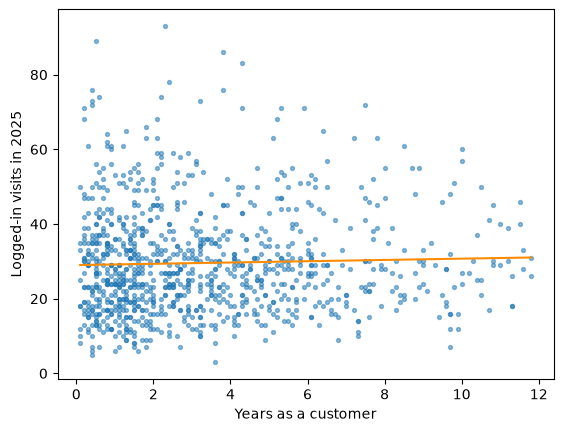

In [6]:
model_vis_ten = smf.ols("visits_2025 ~ tenure_years", data=customers).fit()
print(model_vis_ten.summary())

b0, b1 = model_vis_ten.params["Intercept"], model_vis_ten.params["tenure_years"]
lo, hi = model_vis_ten.conf_int().loc["tenure_years"]
print(f"n = {int(model_vis_ten.nobs)}, b0 = {b0:.2f}, b1 = {b1:.3f}, s_b1 = {model_vis_ten.bse['tenure_years']:.3f}, "
      f"interval {lo:.3f} to {hi:.3f}")
print(f"t = {model_vis_ten.tvalues['tenure_years']:.3f}, p = {model_vis_ten.pvalues['tenure_years']:.3f}")
print(f"R2 = {model_vis_ten.rsquared:.3f}, s_e = {np.sqrt(model_vis_ten.scale):.2f}")

plt.scatter(customers["tenure_years"], customers["visits_2025"], s=8, alpha=0.5)
xs = np.array([customers["tenure_years"].min(), customers["tenure_years"].max()])
plt.plot(xs, b0 + b1 * xs, color="darkorange")
plt.xlabel("Years as a customer")
plt.ylabel("Logged-in visits in 2025")
plt.show()


**Your answer:**

RetailCorp cannot conclude that long-time customers visit more.

We regressed the number of logged-in visits in 2025 on years as a customer for a random sample of 1,000 customers (OLS). Customers one year apart in tenure differ in average visits by 0.17 (95% interval −0.15 to 0.49; $t$ = 1.05, $p$ = 0.292). **We do not reject $H_0$: $\beta_1$ = 0** at $\alpha$ = 0.05. Tenure accounts for 0.1% of the variation in visits ($R^2$ = 0.001), and the typical distance from the line is $s_e$ = 13.93 visits, the same as the raw spread of visits.

This does **not** show that visits do not depend on tenure. The data are compatible with a slope of 0, but the 95% interval also includes other slopes: from a small decrease of 0.15 visits per year of tenure up to an increase of 0.49. If a relationship exists, it is too weak for this sample to pin it down. The scatter is wide and the fitted line is almost flat. The result is an association among the customers as they are, not evidence that tenure causes visits.


### Task 4. The slope by hand for Nordjylland

At the oral exam you may be asked to compute or explain the formulas. For the 108 customers in Nordjylland, Python
gave these summary numbers for spend (y) and years as a customer (x):

| Quantity | Value |
|---|---|
| n | 108 |
| x̄ (years) | 3.2343 |
| ȳ (DKK) | 2,063.9757 |
| Σ(x − x̄)² | 845.5632 |
| Σ(x − x̄)(y − ȳ) | 227,879.0198 |
| SSE | 165,730,107.57 |

Compute b<sub>1</sub>, b<sub>0</sub>, s<sub>e</sub>, s<sub>b1</sub> and t with a calculator or with Python as a
calculator (type in the numbers). Find the critical value, decide whether to reject H<sub>0</sub>: β<sub>1</sub> = 0
at α = 0.05, and compute the 95% interval. Then fit the line on the Nordjylland customers and check your numbers
against the output.

**Answer in words.** Write one sentence for a manager about customers in Nordjylland.

<details>
<summary>Hint 1</summary>

b<sub>1</sub> = Σ(x − x̄)(y − ȳ) / Σ(x − x̄)², b<sub>0</sub> = ȳ − b<sub>1</sub>x̄,
s<sub>e</sub> = √(SSE / (n − 2)), s<sub>b1</sub> = s<sub>e</sub> / √Σ(x − x̄)², t = b<sub>1</sub> / s<sub>b1</sub>,
interval b<sub>1</sub> ± t<sub>n−2, 0.025</sub> s<sub>b1</sub>.
</details>

<details>
<summary>Hint 2</summary>

`np.sqrt(...)`, `stats.t.ppf(0.975, df=n - 2)`. For the check, pick the rows with
`customers[customers["region"] == "Nordjylland"]` (see the toolbox) and fit with `smf.ols`.
</details>

In [7]:
# The slope and its standard error by hand, from the given summaries
n = 108
x_bar = 3.2343
y_bar = 2063.9757
sxx = 845.5632
sxy = 227879.0198
sse = 165730107.57

b1 = sxy / sxx
b0 = y_bar - b1 * x_bar
s_e = np.sqrt(sse / (n - 2))
s_b1 = s_e / np.sqrt(sxx)
t_stat = b1 / s_b1
t_crit = stats.t.ppf(0.975, df=n - 2)
lo = b1 - t_crit * s_b1
hi = b1 + t_crit * s_b1
p = 2 * stats.t.sf(np.abs(t_stat), df=n - 2)

print(f"b0 = {b0:.2f}, b1 = {b1:.3f}")
print(f"s_e = {s_e:.2f}, s_b1 = {s_b1:.3f}")
print(f"t = {t_stat:.3f}, t_crit = {t_crit:.3f}, p = {p:.2e}")
print(f"95% interval {lo:.2f} to {hi:.2f}")

# Check against the OLS output for the Nordjylland customers
nord = customers[customers["region"] == "Nordjylland"]
model_nord = smf.ols("spend_2025 ~ tenure_years", data=nord).fit()
print(model_nord.summary())
print(f"n = {int(model_nord.nobs)}, b0 = {model_nord.params['Intercept']:.2f}, "
      f"b1 = {model_nord.params['tenure_years']:.3f}, s_b1 = {model_nord.bse['tenure_years']:.3f}")
print(f"t = {model_nord.tvalues['tenure_years']:.3f}, p = {model_nord.pvalues['tenure_years']:.2e}")
lo, hi = model_nord.conf_int().loc["tenure_years"]
print(f"interval {lo:.2f} to {hi:.2f}")
print(f"R2 = {model_nord.rsquared:.3f}, s_e = {np.sqrt(model_nord.scale):.2f}")


b0 = 1192.33, b1 = 269.500
s_e = 1250.40, s_b1 = 43.001
t = 6.267, t_crit = 1.983, p = 8.06e-09
95% interval 184.25 to 354.75
                            OLS Regression Results                            
Dep. Variable:             spend_2025   R-squared:                       0.270
Model:                            OLS   Adj. R-squared:                  0.263
Method:                 Least Squares   F-statistic:                     39.28
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           8.06e-09
Time:                        13:58:19   Log-Likelihood:                -922.41
No. Observations:                 108   AIC:                             1849.
Df Residuals:                     106   BIC:                             1854.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
---

**Your answer:**

From the given summaries, with $n$ = 108 and $n - 2$ = 106 degrees of freedom:

- $b_1$ = $\sum(x - \bar{x})(y - \bar{y}) / \sum(x - \bar{x})^2$ = 227,879.0198 / 845.5632 = **269.50 DKK per year**
- $b_0$ = $\bar{y} - b_1\bar{x}$ = 2,063.9757 − 269.50 $\times$ 3.2343 = **1,192.33 DKK**
- $s_e$ = $\sqrt{\mathrm{SSE}/(n-2)}$ = $\sqrt{165{,}730{,}107.57 / 106}$ = **1,250.40 DKK**
- $s_{b_1}$ = $s_e / \sqrt{\sum(x - \bar{x})^2}$ = 1,250.40 / $\sqrt{845.5632}$ = **43.00**
- $t$ = $b_1 / s_{b_1}$ = 269.50 / 43.00 = **6.267**
- Critical value: $t_{106,\,0.025}$ = **1.983**. Because $|t|$ = 6.27 > 1.983 ($p < 0.001$), **we reject $H_0$: $\beta_1$ = 0** at $\alpha$ = 0.05.
- 95% interval: $269.50 \pm 1.983 \times 43.00$, that is **184.25 to 354.75 DKK per year**.

Fitting the same line on the 108 Nordjylland customers in the sample gives the same numbers (any difference is only in the last decimals, from rounding in the table). $R^2$ = 0.270.

**For a manager.** Among customers in Nordjylland, those who have been with RetailCorp one year longer spend about 269 DKK more in 2025, on average (95% interval 184 to 355). The association is clearly different from 0, but a typical customer still lies about 1,250 DKK from the line, and the data do not show that tenure itself causes higher spend.


## Extension tasks

### Extension 1. Airline delays

In the airline passenger survey from Workshop 3, regress the arrival delay on the departure delay (both in minutes).
Interpret b<sub>1</sub> and b<sub>0</sub>, and explain why the slope is close to 1 and the intercept close to 0. How
many rows does the model use, and why is that fewer than the number of rows in the file? The file:
`pd.read_csv(url + "airline_survey.csv")`. Put a column name with spaces in `Q('...')` inside the formula.

In [8]:
airline = pd.read_csv(url + "airline_survey.csv")
print("Rows in the file:", len(airline))
print("Missing arrival delay:", airline["Arrival Delay in Minutes"].isna().sum())
print("Missing departure delay:", airline["Departure Delay in Minutes"].isna().sum())

model_delay = smf.ols(
    "Q('Arrival Delay in Minutes') ~ Q('Departure Delay in Minutes')",
    data=airline,
).fit()
print(model_delay.summary())

xname = "Q('Departure Delay in Minutes')"
b0 = model_delay.params["Intercept"]
b1 = model_delay.params[xname]
lo, hi = model_delay.conf_int().loc[xname]
print(f"n = {int(model_delay.nobs)} (file has {len(airline)} rows, "
      f"{len(airline) - int(model_delay.nobs)} dropped)")
print(f"b0 = {b0:.3f}, b1 = {b1:.3f}, s_b1 = {model_delay.bse[xname]:.4f}, "
      f"interval {lo:.3f} to {hi:.3f}")
print(f"t = {model_delay.tvalues[xname]:.2f}, p = {model_delay.pvalues[xname]:.2e}")
print(f"R2 = {model_delay.rsquared:.3f}, s_e = {np.sqrt(model_delay.scale):.2f}")


Rows in the file: 25976
Missing arrival delay: 83
Missing departure delay: 0


                                  OLS Regression Results                                 
Dep. Variable:     Q('Arrival Delay in Minutes')   R-squared:                       0.930
Model:                                       OLS   Adj. R-squared:                  0.930
Method:                            Least Squares   F-statistic:                 3.454e+05
Date:                           Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                                   13:58:19   Log-Likelihood:                -96120.
No. Observations:                          25893   AIC:                         1.922e+05
Df Residuals:                              25891   BIC:                         1.923e+05
Df Model:                                      1                                         
Covariance Type:                       nonrobust                                         
                                      coef    std err          t      P>|t|      [0.025      0.975]


**Your answer:**

$y$ is arrival delay in minutes and $x$ is departure delay in minutes.

The model uses $n$ = 25,893 rows, 83 fewer than the 25,976 rows in the file. That is because `Arrival Delay in Minutes` is missing for 83 passengers, and `smf.ols` drops rows with a missing $y$ or $x$ (the file has no missing departure delays). This is a known issue in the course data README.

$b_1$ = 0.973 minutes of arrival delay per minute of departure delay (95% interval 0.970 to 0.976; $t$ = 587.7, $p < 0.001$). $b_0$ = 0.90 minutes. $R^2$ = 0.930, and $s_e$ = 9.91 minutes.

The slope is close to 1 and the intercept close to 0 because arrival delay is largely the departure delay carried forward: a flight that leaves 10 minutes late typically arrives about 10 minutes late. The intercept of about 0.9 minutes is a small average extra delay en route (a negative intercept would have meant a small average catch-up). The fit is very tight ($R^2$ = 0.93), which is what we expect if most of the arrival delay is just the departure delay passed on. This is a mechanical relationship, not a managerial "effect" we would try to change by itself: the main way to reduce arrival delays is to reduce departure delays.


### Extension 2. Two variables at once?

In the lecture, age and years as a customer each accounted for about 13% of the variation in spend. Does that mean
that together they account for about 26%? Compute the correlation between age and tenure, and write down your guess
and a reason. (Lecture 7 gives the answer.)

In [9]:
r = customers["age"].corr(customers["tenure_years"])
print(f"Correlation between age and tenure: r = {r:.3f}")

# The two simple regressions from the lecture, for the "13% + 13%" comparison
model_age = smf.ols("spend_2025 ~ age", data=customers).fit()
model_ten = smf.ols("spend_2025 ~ tenure_years", data=customers).fit()
print(f"R2 for age alone: {model_age.rsquared:.3f}")
print(f"R2 for tenure alone: {model_ten.rsquared:.3f}")
print(f"Sum of the two R2 values: {model_age.rsquared + model_ten.rsquared:.3f}")

# Preview of Lecture 7: both variables in one model (not required for the guess)
model_both = smf.ols("spend_2025 ~ age + tenure_years", data=customers).fit()
print(f"R2 with both in one model: {model_both.rsquared:.3f}")


Correlation between age and tenure: r = 0.485
R2 for age alone: 0.125
R2 for tenure alone: 0.133
Sum of the two R2 values: 0.258
R2 with both in one model: 0.174


**Your answer:**

The correlation between age and years as a customer is $r$ = 0.485. The two variables move together: older customers have, on average, been customers for longer.

No, they should not account for about 26% together. Each simple regression's $R^2$ is the share of the variation in spend that *that one* $x$ accounts for (age alone $R^2$ = 0.125; tenure alone $R^2$ = 0.133; the two sum to 0.258). Because age and tenure are positively correlated, they share some of the same variation in spend; adding the two $R^2$ values would count that overlap twice. Together they should therefore account for less than 0.26, and more than either variable on its own (about 0.13).

Lecture 7 fits both in one model. A preview of that fit gives $R^2$ = 0.174, which matches this reasoning: more than 13%, but well below 26%.


### Extension 3. The exam assignment

If your group has time left, start on sections 1 to 4 of the exam assignment (link on Moodle).